# 8 · Is the grid fine enough? Front speed versus grid spacing

The notebooks use a grid spacing $\Delta x = 1$. A Fisher–Kolmogorov tumour front has a width of about $\sqrt{D/\alpha}$. When that width is smaller than a grid cell the grid cannot resolve the front, and the front moves at the wrong speed. This notebook measures how wrong.

Fronts in the 2D notebooks are smooth and nearly flat on the scale of a grid cell, so their speed is a one-dimensional property. That allows a 1D grid, which can be refined far beyond what a 2D grid could afford.

For each model the front is started at $x = 0$–$5$ and its position (where $n = 0.5$) is tracked. The measured speed is compared with:
- the **continuum speed** $c^* = 2\sqrt{D\alpha}$, i.e. the right answer;
- the **grid speed** predicted by theory for spacing $\Delta x$ (`ag.lattice_speed`).

The time step is small ($\Delta t \le 0.01$) so that the error comes from the grid, not the time stepping. The models are 3 ($D = 0.001$, $\alpha = 2$), 4 ($D = 0.05$, $\alpha = 1$) and 5 ($D = 0.2$, $\alpha = 1$ at the leading edge, where no vessels have formed yet).

In [1]:
import sys
sys.path.insert(0, "..")    # shared code lives in corrected/angiogenesis.py
import numpy as np
import matplotlib.pyplot as plt
import angiogenesis as ag

In [2]:
def measured_speed(D, alpha, dx, T):
    """Run a 1D Fisher-Kolmogorov front for time T and fit its late-time speed."""
    dt = min(0.01, 0.4 * dx * dx / D)
    length = 5 + 1.2 * T * ag.lattice_speed(D, alpha, dx) + 10
    x = np.arange(0, length, dx)
    n = (x < 5).astype(float)
    times, positions = [], []
    every = max(1, int(round(1 / dt)))
    for step in range(1, int(round(T / dt)) + 1):
        n = ag.fk_step(n, D, alpha, 1.0, dt, dx, bc="noflux")
        if step % every == 0:
            times.append(step * dt)
            positions.append(ag.front_position(n, dx))
    k = int(len(times) * 0.6)                 # fit the last 40 % of the run
    return np.polyfit(times[k:], positions[k:], 1)[0]

models = {
    "model 3 (D = 0.001, α = 2)": (0.001, 2, [1, 0.5, 0.25, 0.1, 0.05, 0.02, 0.01, 0.005], 100),
    "model 4 (D = 0.05, α = 1)":  (0.05, 1, [1, 0.5, 0.25, 0.1, 0.05, 0.02], 80),
    "model 5 (D = 0.2, α = 1)":   (0.2, 1, [1, 0.5, 0.25, 0.1, 0.05], 60),
}
results = {}
for name, (D, alpha, dxs, T) in models.items():
    c = ag.continuum_speed(D, alpha)
    results[name] = [(dx, measured_speed(D, alpha, dx, T) / c, ag.lattice_speed(D, alpha, dx) / c) for dx in dxs]
    print(f"{name}: front width sqrt(D/alpha) = {np.sqrt(D / alpha):.3g} grid units")
    for dx, meas, lat in results[name]:
        print(f"   dx = {dx:<6g} measured speed = {meas:5.3f} x c*    predicted = {lat:5.3f} x c*")

model 3 (D = 0.001, α = 2): front width sqrt(D/alpha) = 0.0224 grid units
   dx = 1      measured speed = 4.391 x c*    predicted = 4.475 x c*
   dx = 0.5    measured speed = 2.826 x c*    predicted = 2.885 x c*
   dx = 0.25   measured speed = 1.934 x c*    predicted = 1.974 x c*
   dx = 0.1    measured speed = 1.325 x c*    predicted = 1.353 x c*
   dx = 0.05   measured speed = 1.113 x c*    predicted = 1.138 x c*
   dx = 0.02   measured speed = 1.006 x c*    predicted = 1.030 x c*
   dx = 0.01   measured speed = 0.984 x c*    predicted = 1.008 x c*
   dx = 0.005  measured speed = 0.978 x c*    predicted = 1.002 x c*


model 4 (D = 0.05, α = 1): front width sqrt(D/alpha) = 0.224 grid units
   dx = 1      measured speed = 1.324 x c*    predicted = 1.353 x c*
   dx = 0.5    measured speed = 1.114 x c*    predicted = 1.138 x c*
   dx = 0.25   measured speed = 1.023 x c*    predicted = 1.045 x c*
   dx = 0.1    measured speed = 0.987 x c*    predicted = 1.008 x c*
   dx = 0.05   measured speed = 0.981 x c*    predicted = 1.002 x c*
   dx = 0.02   measured speed = 0.986 x c*    predicted = 1.000 x c*


model 5 (D = 0.2, α = 1): front width sqrt(D/alpha) = 0.447 grid units
   dx = 1      measured speed = 1.109 x c*    predicted = 1.138 x c*
   dx = 0.5    measured speed = 1.018 x c*    predicted = 1.045 x c*
   dx = 0.25   measured speed = 0.987 x c*    predicted = 1.012 x c*
   dx = 0.1    measured speed = 0.977 x c*    predicted = 1.002 x c*
   dx = 0.05   measured speed = 0.980 x c*    predicted = 1.001 x c*


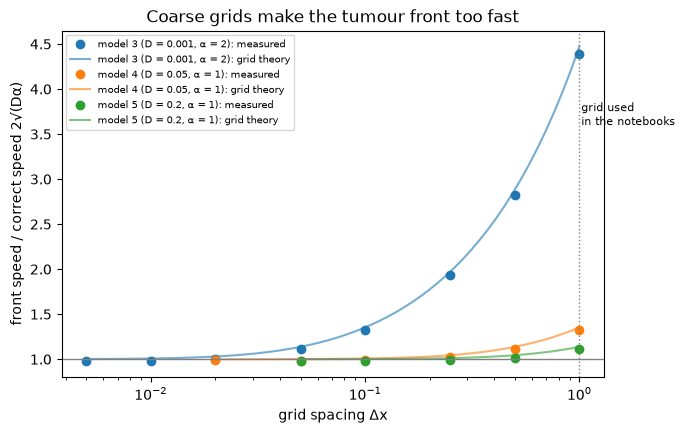

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, rows in results.items():
    dx, meas, lat = map(np.array, zip(*rows))
    line, = ax.plot(dx, meas, "o", label=f"{name}: measured")
    fine = np.logspace(np.log10(dx.min()), 0, 60)
    D, alpha = models[name][:2]
    ax.plot(fine, [ag.lattice_speed(D, alpha, h) / ag.continuum_speed(D, alpha) for h in fine],
            "-", color=line.get_color(), alpha=0.6, label=f"{name}: grid theory")
ax.axhline(1, color="grey", lw=1)
ax.axvline(1, color="grey", lw=1, ls=":")
ax.text(1.02, 3.6, "grid used\nin the notebooks", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("grid spacing Δx")
ax.set_ylabel("front speed / correct speed 2√(Dα)")
ax.legend(fontsize=7)
ax.set_title("Coarse grids make the tumour front too fast")
plt.show()

**Reading the result.**

- **At the spacing the notebooks use ($\Delta x = 1$), the tumour front is too fast:** about 4.4× in model 3, 1.3× in model 4 and 1.1× in model 5. So most of the spreading seen in model 3 comes from the grid, not from diffusion.
- **The grid theory predicts the measurements to within about 2–3 %**, so the error is understood rather than mysterious.
- **On fine grids the measured speed settles about 2 % below $2\sqrt{D\alpha}$.** That is not a grid error. Fronts like these approach their final speed only slowly, with a correction that shrinks like $1/t$.
- **Rule of thumb from these numbers:**
  - a spacing about equal to the front width, $\Delta x \lesssim \sqrt{D/\alpha}$, keeps the speed error near 5 %;
  - half of that keeps it near 1 %.
- **What this means for the 2D models:**
  - model 3 would need $\Delta x \approx 0.02$, a 10,000 × 10,000 grid for the same domain, which is not practical;
  - model 4 ($\Delta x \approx 0.25$, an 800 × 800 grid) and model 5 ($\Delta x \approx 0.5$, 400 × 400) are affordable if quantitative speeds matter.